Identify the most common words in positive vs. negative reviews by analyzing co-occurrence patterns, performing sentiment-specific n-gram extraction, and leveraging contextual embeddings like Word2Vec or GloVe for deeper semantic insights.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

In [2]:
df = pd.read_pickle("saved_data/womens_clothing_final.pkl")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
print("\nColumns:",df.columns.tolist())

Dataset loaded successfully!
Dataset Shape: (23483, 49)

Columns: ['product_id', 'category', 'subcategory1', 'subcategory2', 'location', 'channel', 'customer_age', 'review_title', 'review_text', 'rating', 'recommend_flag', 'vader_negative', 'vader_neutral', 'vader_positive', 'vader_compound', 'vader_sentiment_score', 'vader_sentiment_label', 'age_cluster_raw', 'age_group', 'sentiment_target', 'text_clean', 'text_stemmed', 'text_lemmatized', 'review_title_binned', 'category_General', 'category_General Petite', 'category_Initmates', 'subcategory1_Bottoms', 'subcategory1_Dresses', 'subcategory1_Intimate', 'subcategory1_Jackets', 'subcategory1_Tops', 'subcategory1_Trend', 'location_Bangalore', 'location_Chennai', 'location_Gurgaon', 'location_Mumbai', 'channel_Mobile', 'channel_Web', 'vader_sentiment_label_Negative', 'vader_sentiment_label_Neutral', 'vader_sentiment_label_Positive', 'age_group_Age Group 1', 'age_group_Age Group 2', 'age_group_Age Group 3', 'age_group_Age Group 4', 'text_ne

Prepare positive and negative reviews

In [3]:
word_analysis_df = df[['review_text', 'rating', 'text_domain_cleaned']].copy()

word_analysis_df.dropna(subset=["review_text", "rating", "text_domain_cleaned"], inplace=True)

word_analysis_df['text_domain_cleaned'] = (word_analysis_df['text_domain_cleaned'].astype(str).str.strip())

word_analysis_df = word_analysis_df[word_analysis_df['text_domain_cleaned'] != ""].copy()

# Separate sentiment groups
positive_reviews = word_analysis_df[word_analysis_df["rating"] >= 4].copy()

negative_reviews = word_analysis_df[word_analysis_df["rating"] <= 2].copy()

print("Positive reviews:", len(positive_reviews))
print("Negative reviews:", len(negative_reviews))
print("Total selected reviews:", len(positive_reviews) + len(negative_reviews))

print("\nPositive review sample:")
print(positive_reviews["text_domain_cleaned"].iloc[0])

print("\nNegative review sample:")
print(negative_reviews["text_domain_cleaned"].iloc[0])

Positive reviews: 18205
Negative reviews: 2407
Total selected reviews: 20612

Positive review sample:
absolutely wonderful silky sexy comfortable

Negative review sample:
love tracy reese dresses one not very petite just 5 feet tall usually wear 0p brand dress very pretty package lot dress skirt long very full so overwhelmed small frame not stranger alterations shortening narrowing skirt take away embellishment garment love color idea style just not work returned dress


Most common words in positive vs. negative reviews

In [4]:
from sklearn.feature_extraction.text import CountVectorizer

In [5]:
def get_common_words(reviews, top_n=20):
    vectorizer = CountVectorizer(
        stop_words='english',
        ngram_range=(1, 1),
        max_features=10000
    )

    x = vectorizer.fit_transform(reviews)

    word_counts = x.sum(axis=0).A1

    word_freq = pd.DataFrame({
        "Word": vectorizer.get_feature_names_out(),
        "Frequency": word_counts
    })

    return word_freq.sort_values(
        by='Frequency',
        ascending=False
    ).head(top_n).reset_index(drop=True)

# Most common positive words
positive_top_words = get_common_words(positive_reviews["text_domain_cleaned"])

# Most common negative words
negative_top_words = get_common_words(negative_reviews["text_domain_cleaned"])

print("TOP 20 POSITIVE WORDS")
display(positive_top_words)

print("\nTOP 20 NEGATIVE WORDS")
display(negative_top_words)

TOP 20 POSITIVE WORDS


,Word,Frequency
0,dress,8032
1,love,7738
2,size,7056
3,fit,5624
4,wear,5418
5,great,5413
6,just,4011
7,color,3623
8,small,3529
9,perfect,3516



TOP 20 NEGATIVE WORDS


,Word,Frequency
0,dress,1124
1,fabric,708
2,fit,686
3,size,676
4,just,667
5,small,517
6,look,512
7,ordered,512
8,really,474
9,love,456


Sentiment-specific bigrams and trigrams

In [7]:
def get_top_ngrams(reviews, ngram_range, top_n=20):

    vectorizer = CountVectorizer(
        stop_words="english",
        ngram_range=ngram_range,
        min_df=2,
        max_features=20000
    )

    x = vectorizer.fit_transform(reviews)

    frequencies = x.sum(axis=0).A1

    results = pd.DataFrame({
        "Ngram": vectorizer.get_feature_names_out(),
        "Frequency": frequencies
    })

    return results.sort_values(
        "Frequency", ascending=False
    ).head(top_n).reset_index(drop=True)


# Positive reviews
positive_bigrams = get_top_ngrams(
    positive_reviews["text_domain_cleaned"], (2, 2)
)

positive_trigrams = get_top_ngrams(
    positive_reviews["text_domain_cleaned"], (3, 3)
)

# Negative reviews
negative_bigrams = get_top_ngrams(
    negative_reviews["text_domain_cleaned"], (2, 2)
)

negative_trigrams = get_top_ngrams(
    negative_reviews["text_domain_cleaned"], (3, 3)
)

print("POSITIVE REVIEW - TOP BIGRAMS")
display(positive_bigrams)

print("POSITIVE REVIEW - TOP TRIGRAMS")
display(positive_trigrams)

print("NEGATIVE REVIEW - TOP BIGRAMS")
display(negative_bigrams)

print("NEGATIVE REVIEW - TOP TRIGRAMS")
display(negative_trigrams)


POSITIVE REVIEW - TOP BIGRAMS


,Ngram,Frequency
0,true size,1201
1,love dress,649
2,looks great,571
3,usually wear,554
4,fit perfectly,538
5,fits perfectly,477
6,size small,427
7,just right,405
8,usual size,394
9,highly recommend,362


POSITIVE REVIEW - TOP TRIGRAMS


,Ngram,Frequency
0,fits true size,265
1,fit true size,192
2,runs true size,138
3,love love love,134
4,usually wear size,111
5,ordered usual size,79
6,small fit perfectly,72
7,looks great jeans,68
8,small fits perfectly,64
9,usually wear small,61


NEGATIVE REVIEW - TOP BIGRAMS


,Ngram,Frequency
0,wanted love,125
1,really wanted,81
2,usually wear,66
3,size small,54
4,true size,51
5,ordered size,48
6,wanted like,44
7,runs large,40
8,usual size,40
9,love dress,39


NEGATIVE REVIEW - TOP TRIGRAMS


,Ngram,Frequency
0,really wanted love,40
1,really wanted like,28
2,wanted love dress,24
3,fit true size,18
4,usually wear size,16
5,ordered usual size,16
6,high hopes dress,9
7,looks cute model,9
8,looks great model,8
9,usual size small,8


Interpretation

Positive reviews
- true size, fits perfectly, fit great — customers are satisfied with sizing and fit.
- soft comfortable, fabric soft, super soft — positive fabric and comfort experiences.
- highly recommend, absolutely love — strong satisfaction.


Negative reviews
- wanted love, really wanted, wanted like — customers expected to like the product but were disappointed.
- runs large, runs small, arm holes — sizing and design concerns.
- poor quality, just work — dissatisfaction with product quality or suitability.

Word co-occurrence analysis

In [8]:
from scipy.sparse import triu


In [10]:
def  get_cooccurrence(reviews, top_n=20):
    vectorizer = CountVectorizer(
        stop_words="english",
        binary=True,
        min_df=5,
        max_features=500
    )

    x = vectorizer.fit_transform(reviews)

    # Count how many reviews contain each word pair
    co_matrix = x.T @ x

    # Keep only unique pairs, excluding diagonal
    upper = triu(co_matrix, k=1).tocoo()

    words = vectorizer.get_feature_names_out()
    total_reviews = x.shape[0]

    results = pd.DataFrame({
        "Word 1": words[upper.row],
        "Word 2": words[upper.col],
        "Cooccurrence Count": upper.data
    })

    results["Review Percentage"] = (
        results["Cooccurrence Count"] / total_reviews * 100
    ).round(2)

    return results.sort_values(
        "Cooccurrence Count",
        ascending=False
    ).head(top_n).reset_index(drop=True)


# Positive co-occurrence
positive_cooccurrence = get_cooccurrence(
    positive_reviews["text_domain_cleaned"]
)

# Negative co-occurrence
negative_cooccurrence = get_cooccurrence(
    negative_reviews["text_domain_cleaned"]
)

print("TOP POSITIVE WORD CO-OCCURRENCES")
display(positive_cooccurrence)

print("TOP NEGATIVE WORD CO-OCCURRENCES")
display(negative_cooccurrence)


TOP POSITIVE WORD CO-OCCURRENCES


,Word 1,Word 2,Cooccurrence Count,Review Percentage
0,fit,size,1945,10.68
1,love,size,1837,10.09
2,love,wear,1742,9.57
3,fit,love,1728,9.49
4,great,love,1686,9.26
5,dress,love,1681,9.23
6,size,wear,1545,8.49
7,dress,size,1501,8.24
8,dress,wear,1421,7.81
9,fit,great,1375,7.55


TOP NEGATIVE WORD CO-OCCURRENCES


,Word 1,Word 2,Cooccurrence Count,Review Percentage
0,fit,size,201,8.35
1,ordered,size,181,7.52
2,dress,fabric,167,6.94
3,dress,just,167,6.94
4,fit,ordered,164,6.81
5,size,small,155,6.44
6,fit,just,154,6.40
7,dress,fit,153,6.36
8,fabric,just,152,6.31
9,fit,small,141,5.86


Word2Vec semantic analysis

In [14]:
%pip install gensim

   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/24.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/24.4 MB ? eta -:--:--
   -----------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
import gensim
from gensim.models import Word2Vec

print("Gensim version:", gensim.__version__)
print("Word2Vec imported successfully!")

Gensim version: 4.4.0
Word2Vec imported successfully!


Prepare tokenized reviews

In [17]:
# Prepare text for Word2Vec
sentences = (
    word_analysis_df['text_domain_cleaned']
    .astype(str)
    .apply(lambda text: text.split())
    .tolist()
)
# Remove empty sentences
sentences = [words for words in sentences if len(words) > 1]

print("Total sentences:", len(sentences))
print("Example tokenized review:", sentences[0])
print("Total words:", sum(len(words) for words in sentences))
print("Unique words:", len(set(word for sentence in sentences for word in sentence)))

Total sentences: 23483
Example tokenized review: ['absolutely', 'wonderful', 'silky', 'sexy', 'comfortable']
Total words: 708071
Unique words: 15257


Train Word2Vec model

In [19]:
from gensim.models import Word2Vec

In [21]:
word2vec_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=5,
    workers=4,
    sg=1,
    epochs=15,
    seed=42
)

print("Word2Vec training completed!")
print("Vocabulary size:", len(word2vec_model.wv))
print("Vector dimensions:", word2vec_model.wv.vector_size)


Word2Vec training completed!
Vocabulary size: 4913
Vector dimensions: 100


Find semantically similar words

In [22]:
target_words = [
    "soft",
    "comfortable",
    "fit",
    "size",
    "quality",
    "small",
    "large",
    "love",
    "fabric",
    "dress"
]

for word in target_words:
    print(f"\nSimilar words to '{word}':")

    if word in word2vec_model.wv:
        similar_words = word2vec_model.wv.most_similar(
            word,
            topn=10
        )

        for similar_word, similarity in similar_words:
            print(f"{similar_word}: {similarity:.3f}")
    else:
        print("Word not found in vocabulary.")


Similar words to 'soft':
luxuriously: 0.694
yummy: 0.676
velvety: 0.638
heavenly: 0.634
comfy: 0.631
cottony: 0.630
buttery: 0.629
boucle: 0.627
waffle: 0.625
brushed: 0.622

Similar words to 'comfortable':
comfy: 0.839
uber: 0.692
preppy: 0.642
packs: 0.639
pjs: 0.596
butter: 0.592
versitile: 0.585
confortable: 0.583
comf: 0.577
versatile: 0.574

Similar words to 'fit':
fits: 0.747
proportioned: 0.616
28p: 0.614
size: 0.614
29s: 0.611
worked: 0.586
107lbs: 0.586
5.4: 0.582
34aa: 0.576
accommodates: 0.574

Similar words to 'size':
size-: 0.787
29s: 0.723
133: 0.711
big-: 0.688
12p: 0.681
size.: 0.680
siz: 0.679
28p: 0.675
lg: 0.673
0/2: 0.672

Similar words to 'quality':
workmanship: 0.603
construction: 0.578
craftsmanship: 0.569
execution: 0.565
fabrication: 0.563
qu: 0.556
finishing: 0.554
lacking: 0.553
maintenance: 0.547
value: 0.523

Similar words to 'small':
large: 0.813
small-: 0.762
0/2: 0.745
medium: 0.719
5.3: 0.715
large-: 0.699
117lbs: 0.695
28p: 0.690
118lbs: 0.682
xsmall

Compare positive and negative word contexts

In [24]:
def get_word_rates(reviews):
    vectorizer = CountVectorizer(
        stop_words="english",
        min_df=5,
        max_features=10000,
        binary=True
    )

    x = vectorizer.fit_transform(reviews)

    word_counts = x.sum(axis=0).A1
    total_reviews = x.shape[0]

    return pd.DataFrame({
        "Word": vectorizer.get_feature_names_out(),
        "Review Rate (%)": word_counts / total_reviews * 100
    })

positive_rates = get_word_rates(positive_reviews["text_domain_cleaned"])

negative_rates = get_word_rates(negative_reviews["text_domain_cleaned"])

comparison = positive_rates.merge(
    negative_rates,
    on='Word',
    how='outer',
    suffixes=("_Positive", "_Negative")
).fillna(0)

comparison["Difference"] = (comparison["Review Rate (%)_Positive"] - comparison["Review Rate (%)_Negative"])

print("Words more associated with positive reviews:")

display(comparison.sort_values("Difference", ascending=False).head(15))

print("Words more associated with negative reviews:")
display(comparison.sort_values("Difference", ascending=True).head(15))

Words more associated with positive reviews:


,Word,Review Rate (%)_Positive,Review Rate (%)_Negative,Difference
2051,love,34.995880,16.825924,18.169956
1594,great,25.053557,10.137100,14.916457
2433,perfect,17.248009,4.570004,12.678005
821,comfortable,14.984894,3.157457,11.827437
2016,little,15.484757,5.442459,10.042297
1384,fits,13.424883,3.406730,10.018153
3781,wear,25.460038,15.828833,9.631206
3158,soft,15.276023,5.650187,9.625836
3072,size,29.085416,21.354383,7.731033
1852,jeans,10.024718,2.742002,7.282716


Words more associated with negative reviews:


,Word,Review Rate (%)_Positive,Review Rate (%)_Negative,Difference
2029,looked,3.185938,13.793103,-10.607166
1093,disappointed,0.922823,10.427919,-9.505095
3778,way,5.421587,13.543830,-8.122243
1304,fabric,15.852788,23.971749,-8.118961
3750,wanted,2.653117,10.012464,-7.359346
1746,huge,1.049162,7.935189,-6.886027
3656,unfortunately,1.235924,7.893644,-6.657719
2788,return,1.889591,8.226007,-6.336417
2335,ordered,13.551222,19.734109,-6.182887
2110,material,9.640209,15.662651,-6.022442


Visualize the findings

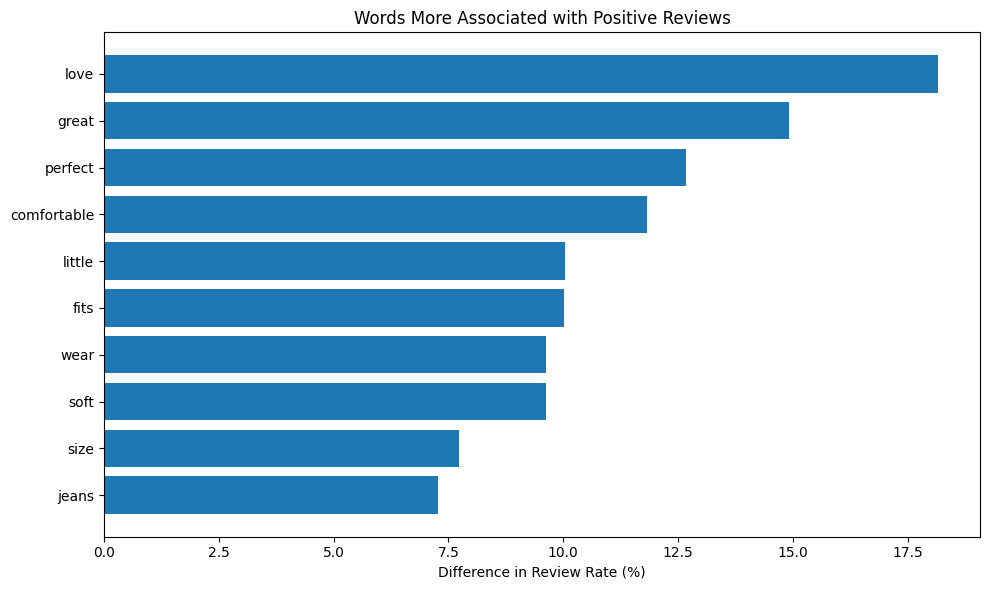

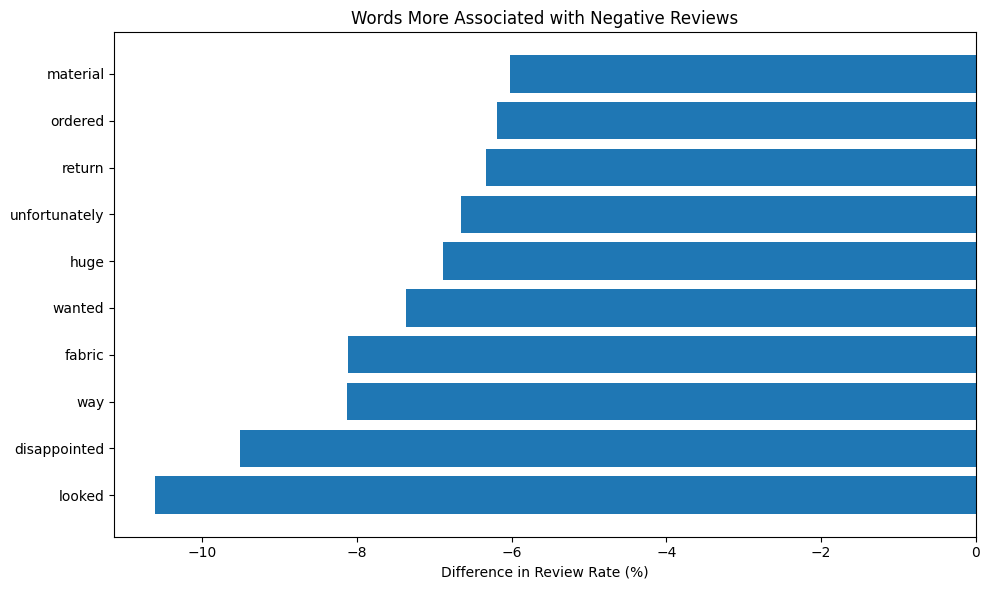

In [26]:

# Select top positive and negative associated words
top_positive = comparison.nlargest(10, "Difference").sort_values("Difference")

top_negative = comparison.nsmallest(10, "Difference").sort_values("Difference")

# Positive-associated words
plt.figure(figsize=(10, 6))
plt.barh(
    top_positive["Word"],
    top_positive["Difference"]
)
plt.xlabel("Difference in Review Rate (%)")
plt.title("Words More Associated with Positive Reviews")
plt.tight_layout()
plt.show()

# Negative-associated words
plt.figure(figsize=(10, 6))
plt.barh(
    top_negative["Word"],
    top_negative["Difference"]
)
plt.xlabel("Difference in Review Rate (%)")
plt.title("Words More Associated with Negative Reviews")
plt.tight_layout()
plt.show()

## Conclusion: Sentiment-Specific N-gram, Co-occurrence and Word2Vec Analysis

In this analysis, sentiment-specific text analysis was performed on 23,483 Women's Clothing Reviews to identify common words, phrases, word relationships, and semantic patterns in positive and negative customer reviews.

Positive and negative reviews were separated using ratings, with ratings of 4–5 classified as positive and ratings of 1–2 classified as negative.

The analysis included:

1. **Unigram Analysis:** Identified frequently occurring words. Positive reviews commonly contained words such as "love", "great", "perfect", "comfortable", and "soft". Negative reviews frequently contained "fabric", "fit", "size", "small", and "quality".

2. **N-gram Analysis:** Extracted bigrams and trigrams to identify meaningful word combinations. Positive phrases included "fits true size", "fit perfectly", and "soft comfortable". Negative phrases included "really wanted love", "runs large", "runs small", and "poor quality".

3. **Word Co-occurrence Analysis:** Identified words frequently appearing together in the same review. The most common pair in both sentiment groups was "fit" and "size". Positive reviews showed stronger associations with words such as "love", "great", and "perfect", while negative reviews showed associations with "ordered", "small", and "fabric".

4. **Word2Vec Analysis:** Trained a Skip-gram Word2Vec model with 100-dimensional vectors, a context window of 5, a minimum word frequency of 5, and 15 training epochs. The model learned semantic relationships such as "fabric–material", "comfortable–comfy", and "love–adore".

5. **Sentiment Comparison:** Normalized word frequencies were compared across positive and negative reviews. Words such as "love", "great", and "comfortable" were more associated with positive reviews, whereas "disappointed", "fabric", "cheap", and "unflattering" were more associated with negative reviews.

6. **Visualization:** Horizontal bar charts were created to compare the words most strongly associated with positive and negative reviews.

### Overall Findings

The analysis indicates that customer satisfaction is strongly associated with comfort, fit, fabric softness, and product appearance. Customer dissatisfaction is frequently associated with fabric quality, sizing issues, unmet expectations, and product returns.

These findings can help fashion retailers understand customer preferences, identify common product-related problems, and improve clothing quality, sizing accuracy, and customer satisfaction.

### Limitations

The sentiment categories were derived from product ratings rather than manually annotated sentiment labels. Word2Vec provides static word embeddings rather than contextual embeddings. Additionally, word frequency and co-occurrence indicate patterns but do not establish causation or always capture the meaning of a complete sentence.